In [1]:
from sklearn.datasets import fetch_kddcup99
import numpy as np 
import pandas as pd 
import time 
import matplotlib.pyplot as plt 

In [2]:
kdd = fetch_kddcup99(subset=None, as_frame=True)

In [3]:
x=kdd.data.copy()
categorical_cols=["protocol_type","service","flag"]
numerical_cols=[]

for i in x.columns:
    if i not in categorical_cols:
        numerical_cols.append(i)


for col in numerical_cols:
    x[col]=pd.to_numeric(x[col],errors="raise").astype(np.float32)

x=pd.get_dummies(x,columns=categorical_cols,dtype=np.float32)
x=x.astype(np.float32,copy=False)

x=x.loc[:,x.nunique(dropna=False)>1]

mat=x.to_numpy(dtype=np.float32,copy=False)
mn=mat.min(axis=0)
mx=mat.max(axis=0)

D=(mat-mn)/(mx-mn)
D=D.astype(np.float32,copy=False)

n,d=D.shape

print("Number of rows (n):", n)
print("Number of columns (d):", d)
print("Shape of D:", D.shape)
print("Data type:", D.dtype)


Number of rows (n): 494021
Number of columns (d): 116
Shape of D: (494021, 116)
Data type: float32


In [4]:
y = (kdd.target != b'normal.').to_numpy(dtype=float)

In [5]:
def compute_mat_prod(h,sigma,mat,m):
    mat=np.asarray(mat,dtype=np.float32)
    is_vector=(mat.ndim==1)
    if is_vector:
        mat=mat.reshape(-1,1)
    
    n,d=mat.shape 

    ans=np.zeros((m,d),dtype=np.float32) 

    # for i in range(n):
    #     ans[h[i]]+=(sigma[i]*mat[i])

    np.add.at(ans,h,sigma[:,None]*mat)
    return ans    

# Part a)

In [6]:
start=time.perf_counter()

result=np.linalg.lstsq(D,y,rcond=None)

end=time.perf_counter()

b,residuals,rank,singular_vals=result 

time_taken=end-start

diff=np.matmul(D,b)-y 
loss=np.dot(diff,diff)
print("Loss: ",loss)
print("Time to compute b: ",time_taken, "seconds")

Loss:  2949.7888148558663
Time to compute b:  4.889946000002965 seconds


# Part b)

In [7]:
def run_random_projection(D,y,b,m,rng):
    start=time.perf_counter()

    h=rng.integers(0,m,size=n)
    sigma=rng.choice([-1, 1],size=n).astype(np.float32)

    y=np.asarray(y,dtype=np.float32).reshape(-1)
    sd=compute_mat_prod(h,sigma,D,m)
    sy=compute_mat_prod(h,sigma,y,m)
    sy=np.asarray(sy).reshape(-1)


    result=np.linalg.lstsq(sd,sy,rcond=None)

    end=time.perf_counter()

    a,residuals,rank,singular_vals=result 
    a=np.asarray(a).reshape(-1)

    # original loss using projected solution
    d1=np.matmul(D,a)-y
    loss_projection=np.dot(d1,d1)

    # original least squares loss
    d2=np.matmul(D,b)-y 
    loss_real=np.dot(d2,d2)

    # skteched loss 
    sd1=np.matmul(sd,a)-sy
    sketched_loss=np.dot(sd1,sd1)

    ratio=loss_projection/loss_real
    time_diff=end-start

    return loss_projection,loss_real,sketched_loss,ratio,time_diff




In [8]:
m_vals=[50,100,200,500,1000,2000,5000]

res={}
n,d=D.shape

rng_b=np.random.default_rng(303)

for m in m_vals:
    res[m]=[]
    for i in range(5):
        lp,lr,sl,ratio,time_diff=run_random_projection(D,y,b,m,rng_b)
        res[m].append([lp,lr,sl,ratio,time_diff])

    print(f"m = {m}:")
    print(np.array(res[m]))

m = 50:
[[8.30815234e+03 2.94978881e+03 5.82748783e-09 2.81652446e+00
  1.18690310e+00]
 [7.33590283e+03 2.94978881e+03 4.01632860e-09 2.48692476e+00
  1.00348670e+00]
 [1.58088594e+04 2.94978881e+03 6.98491931e-09 5.35931905e+00
  1.00502650e+00]
 [1.07900713e+04 2.94978881e+03 6.23236929e-09 3.65791315e+00
  9.47694200e-01]
 [1.16800459e+04 2.94978881e+03 6.55018084e-09 3.95962105e+00
  4.55483400e+00]]
m = 100:
[[4.11524727e+04 2.94978881e+03 5.18789420e-08 1.39509895e+01
  6.61707070e+00]
 [3.65465117e+04 2.94978881e+03 4.05023712e-08 1.23895350e+01
  6.88740630e+00]
 [3.31222656e+04 2.94978881e+03 3.16513251e-08 1.12286905e+01
  1.00526060e+00]
 [4.20849336e+04 2.94978881e+03 2.76008905e-08 1.42671005e+01
  1.06739470e+00]
 [2.51370215e+04 2.94978881e+03 7.34962669e-08 8.52163428e+00
  1.01425890e+00]]
m = 200:
[[6.91958496e+03 2.94978881e+03 1.31532068e+03 2.34578995e+00
  1.05311420e+00]
 [6.07601660e+03 2.94978881e+03 1.28145923e+03 2.05981410e+00
  9.88445400e-01]
 [7.49335498

In [9]:
rank_D=rank
baseline_time=time_taken

records=[]

for m in m_vals:
    for i,values in enumerate(res[m]):
        lp,lr,sl,ratio,t=values

        records.append({
            "m": m,
            "Run": i + 1,
            "Loss(D,y,a_tilde)": lp,
            "Loss(D,y,b)": lr,
            "Sketched Loss": sl,
            "Loss Ratio": ratio,
            "Time (seconds)": t
        })

results_df=pd.DataFrame(records)

print("Results for all 35 experiments:")
print(results_df.to_string(index=False))

Results for all 35 experiments:
   m  Run  Loss(D,y,a_tilde)  Loss(D,y,b)  Sketched Loss  Loss Ratio  Time (seconds)
  50    1        8308.152344  2949.788815   5.827488e-09    2.816524        1.186903
  50    2        7335.902832  2949.788815   4.016329e-09    2.486925        1.003487
  50    3       15808.859375  2949.788815   6.984919e-09    5.359319        1.005026
  50    4       10790.071289  2949.788815   6.232369e-09    3.657913        0.947694
  50    5       11680.045898  2949.788815   6.550181e-09    3.959621        4.554834
 100    1       41152.472656  2949.788815   5.187894e-08   13.950989        6.617071
 100    2       36546.511719  2949.788815   4.050237e-08   12.389535        6.887406
 100    3       33122.265625  2949.788815   3.165133e-08   11.228690        1.005261
 100    4       42084.933594  2949.788815   2.760089e-08   14.267101        1.067395
 100    5       25137.021484  2949.788815   7.349627e-08    8.521634        1.014259
 200    1        6919.584961  294

In [10]:
summary=results_df.groupby("m").agg(
    mean_loss=("Loss(D,y,a_tilde)", "mean"),
    mean_ratio=("Loss Ratio", "mean"),
    min_ratio=("Loss Ratio", "min"),
    max_ratio=("Loss Ratio", "max"),
    mean_sketched_loss=("Sketched Loss", "mean"),
    mean_time=("Time (seconds)", "mean")
)

print("\nSummary for each m:")
print(summary.to_string())


Summary for each m:
         mean_loss  mean_ratio  min_ratio  max_ratio  mean_sketched_loss  mean_time
m                                                                                  
50    10784.606445    3.656060   2.486925   5.359319        5.922257e-09   1.739589
100   35608.640625   12.071590   8.521634  14.267101        4.502596e-08   3.318278
200    6761.251465    2.292114   1.903165   2.611498        1.259123e+03   1.085186
500    3903.455566    1.323300   1.252126   1.383291        2.263204e+03   1.067744
1000   3277.123779    1.110969   1.091572   1.125408        2.674321e+03   0.987083
2000   3139.863037    1.064437   1.054949   1.072514        2.809005e+03   1.130645
5000   3016.932861    1.022762   1.016905   1.030065        2.826472e+03   1.142586


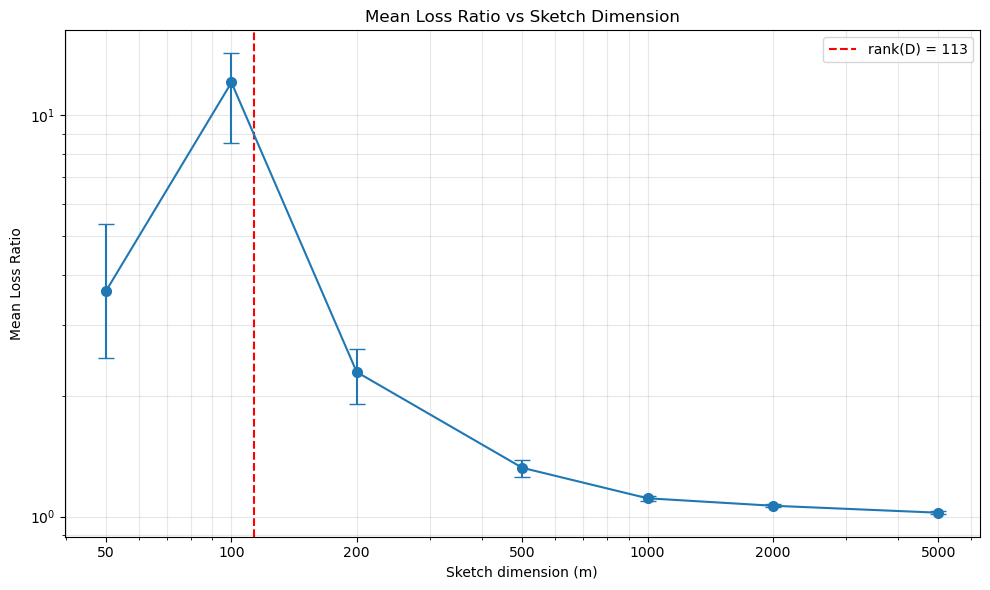

In [11]:
mean = summary["mean_ratio"].values
minimum = summary["min_ratio"].values
maximum = summary["max_ratio"].values

lower_error = mean - minimum
upper_error = maximum - mean

plt.figure(figsize=(10, 6))

plt.errorbar(
    m_vals,
    mean,
    yerr=[lower_error, upper_error],
    fmt='o-',
    capsize=6,
    markersize=7
)

plt.axvline(
    x=rank_D,
    linestyle="--",
    color="red",
    label=f"rank(D) = {rank_D}"
)

plt.xscale("log")
plt.yscale("log")

# Explicitly show all m values
plt.xticks(m_vals, [str(m) for m in m_vals])

plt.xlabel("Sketch dimension (m)")
plt.ylabel("Mean Loss Ratio")
plt.title("Mean Loss Ratio vs Sketch Dimension")

plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

Below the rank of \(D\), the sketched loss is nearly zero, but the original loss ratio can be quite large. Above the rank of \(D\), the sketched loss becomes nonzero and increases towards the original minimum loss, while the original loss ratio approaches 1. Thus, increasing the sketch dimension improves the quality of the approximation

# Part c) 

In [12]:
print("Time to compute b using original D:",
      baseline_time, "seconds")

print("\nComparison of computation times:")

time_comparison = pd.DataFrame({
    "Mean Sketch Time (sec)": summary["mean_time"],
})

time_comparison["Time to compute b (sec)"] = baseline_time

time_comparison["Speedup"] = (
    baseline_time / time_comparison["Mean Sketch Time (sec)"]
)

print(time_comparison.to_string())

Time to compute b using original D: 4.889946000002965 seconds

Comparison of computation times:
      Mean Sketch Time (sec)  Time to compute b (sec)   Speedup
m                                                              
50                  1.739589                 4.889946  2.810978
100                 3.318278                 4.889946  1.473640
200                 1.085186                 4.889946  4.506090
500                 1.067744                 4.889946  4.579697
1000                0.987083                 4.889946  4.953934
2000                1.130645                 4.889946  4.324917
5000                1.142586                 4.889946  4.279717


# Part d) 

In [13]:
v=np.matmul(D,b)-y 
v_norm_sq=np.dot(v,v)

mvals=[50,500,5000]


ratios_d={}

rng=np.random.default_rng(404)

for m in mvals:
    ratios_d[m]=[]
    for i in range(100):
        h=rng.integers(0, m, size=n)
        sigma=rng.choice([-1, 1],size=n).astype(np.float32)

        Sv=compute_mat_prod(h,sigma,v,m).reshape(-1)

        ratio=np.dot(Sv,Sv)/v_norm_sq

        ratios_d[m].append(ratio)

    print(f"\nm = {m}")
    print("Mean:", np.mean(ratios_d[m]))
    print("Standard deviation:", np.std(ratios_d[m], ddof=1))


m = 50
Mean: 1.0002555254720251
Standard deviation: 0.2056145207902702

m = 500
Mean: 1.0052634093017534
Standard deviation: 0.06796949357380269

m = 5000
Mean: 0.9999223721531688
Standard deviation: 0.01844073636461993


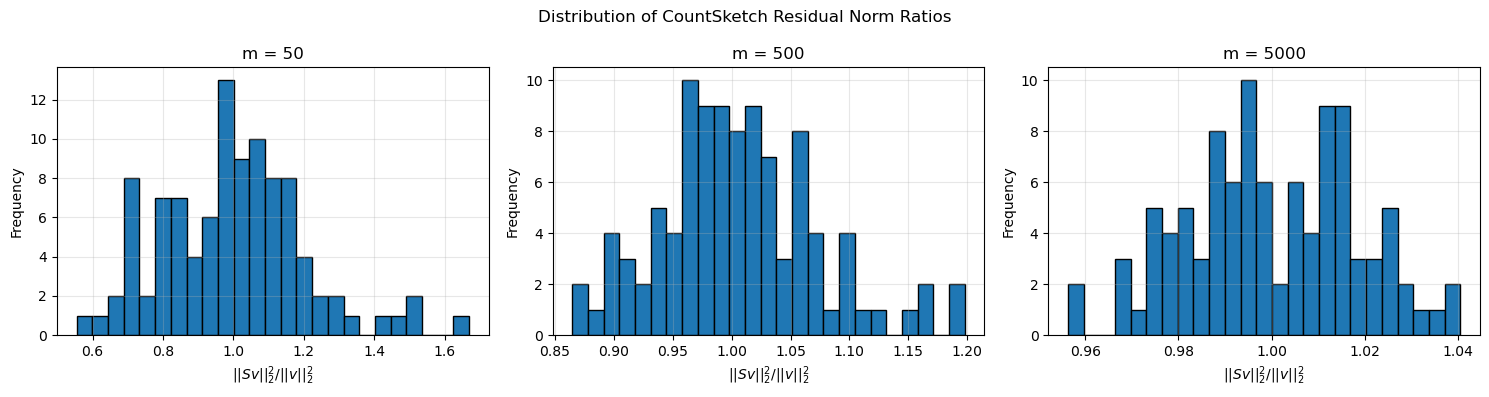

In [14]:
fig,axes=plt.subplots(1,3,figsize=(15,4))

for i,m in enumerate(mvals):
    axes[i].hist(
        ratios_d[m],
        bins=25,
        edgecolor="black"
    )

    axes[i].set_title(f"m = {m}")
    axes[i].set_xlabel(r"$||Sv||_2^2 / ||v||_2^2$")
    axes[i].set_ylabel("Frequency")
    axes[i].grid(alpha=0.3)

plt.suptitle("Distribution of CountSketch Residual Norm Ratios")
plt.tight_layout()
plt.show()

In [15]:
summary_d=pd.DataFrame({
    "m": mvals,
    "Mean": [np.mean(ratios_d[m]) for m in mvals],
    "Standard Deviation":[
        np.std(ratios_d[m],ddof=1) for m in mvals
    ]
})

print(summary_d.to_string(index=False))

   m     Mean  Standard Deviation
  50 1.000256            0.205615
 500 1.005263            0.067969
5000 0.999922            0.018441


The mean of the ratio ‖Sv‖₂² / ‖v‖₂² remains approximately 1 for all three values of m. The spread decreases significantly as m increases, meaning the estimated squared norm becomes more concentrated around its expected value of 1. This indicates that the spread of the ratios decreases with increasing sketch dimension. A larger number of buckets reduces the probability of collisions between coordinates, resulting in more consistent estimates of the original squared norm.

# Part e)

In [16]:
subset_rng=np.random.default_rng(42)

subset_indices=subset_rng.choice(D.shape[0],size=50000,replace=False)

D_prime=np.ascontiguousarray(D[subset_indices],dtype=np.float32)
y_prime=np.asarray(y[subset_indices],dtype=np.float32)

n_prime,d_prime=D_prime.shape

print("D_prime shape:",D_prime.shape)
print("y_prime shape:",y_prime.shape)


b_prime,residuals,rank_prime,singular_vals=np.linalg.lstsq(D_prime,y_prime,rcond=None)

diff_prime=D_prime@b_prime-y_prime

loss_b_prime=np.dot(diff_prime.astype(np.float64),diff_prime.astype(np.float64))

print("Rank of D_prime:", rank_prime)
print("Loss(D_prime, y_prime, b_prime):", loss_b_prime)

D_prime shape: (50000, 116)
y_prime shape: (50000,)
Rank of D_prime: 108
Loss(D_prime, y_prime, b_prime): 275.1544606480614


In [17]:
m=500
num_repeats=5

countsketch_results=[]

rng_cs=np.random.default_rng(101)

for i in range(num_repeats):
    start = time.perf_counter()
    h=rng_cs.integers(0, m, size=n_prime)

    sigma=rng_cs.choice([-1, 1],size=n_prime).astype(np.float32)

    SD_prime=compute_mat_prod(h, sigma, D_prime, m)
    Sy_prime=compute_mat_prod(h, sigma, y_prime, m).reshape(-1)

    end=time.perf_counter()

    sketch_time=end-start

    solve_start=time.perf_counter()

    a_tilde,_,_,_=np.linalg.lstsq(SD_prime,Sy_prime,rcond=None)

    solve_end=time.perf_counter()

    solve_time=solve_end-solve_start

    diff=D_prime@a_tilde-y_prime

    loss_tilde=np.dot(diff.astype(np.float64),diff.astype(np.float64))

    ratio=loss_tilde/loss_b_prime

    countsketch_results.append({
        "Run": i+1,
        "Sketch Time": sketch_time,
        "Solve Time": solve_time,
        "Total Time": sketch_time+solve_time,
        "Loss": loss_tilde,
        "Loss Ratio": ratio
    })

    print(
        f"CountSketch Run {i+1}: "
        f"Time = {sketch_time:.4f} sec, "
        f"Ratio = {ratio:.6f}"
    )

countsketch_df=pd.DataFrame(countsketch_results)

print("\nCountSketch Results:")
print(countsketch_df.to_string(index=False))

CountSketch Run 1: Time = 0.0820 sec, Ratio = 1.275426
CountSketch Run 2: Time = 0.0735 sec, Ratio = 1.252478
CountSketch Run 3: Time = 0.0707 sec, Ratio = 1.267566
CountSketch Run 4: Time = 0.0925 sec, Ratio = 1.283990
CountSketch Run 5: Time = 0.0871 sec, Ratio = 1.314374

CountSketch Results:
 Run  Sketch Time  Solve Time  Total Time       Loss  Loss Ratio
   1     0.081969    0.052562    0.134531 350.939094    1.275426
   2     0.073514    0.043150    0.116664 344.625012    1.252478
   3     0.070703    0.042976    0.113678 348.776429    1.267566
   4     0.092525    0.055022    0.147547 353.295600    1.283990
   5     0.087074    0.054335    0.141409 361.655780    1.314374


In [18]:
# Gaussian jl

dense_results=[]
rng_dense=np.random.default_rng(202)

for i in range(num_repeats):
    start=time.perf_counter()

    s=rng_dense.standard_normal(size=(m,n_prime),dtype=np.float32)
    s=s*np.float32(1.0/np.sqrt(m))

    sd_prime=np.matmul(s,D_prime)
    sy_prime=np.matmul(s,y_prime)

    end=time.perf_counter()
    sketch_time=end-start

    solve_start=time.perf_counter()

    a_tilde,_,_,_=np.linalg.lstsq(sd_prime,sy_prime,rcond=None)
    
    solve_end=time.perf_counter()

    solve_time=solve_end-solve_start

    # original loss 
    diff=np.matmul(D_prime,a_tilde)-y_prime 
    loss=np.dot(diff.astype(np.float64),diff.astype(np.float64))

    ratio=loss/loss_b_prime 

    dense_results.append({
        "Run": i + 1,
        "Sketch Time": sketch_time,
        "Solve Time": solve_time,
        "Total Time": sketch_time+solve_time,
        "Loss": loss,
        "Loss Ratio": ratio
    })

    print(
        f"Dense Gaussian Run {i+1}: "
        f"Time = {sketch_time:.4f} sec, "
        f"Ratio = {ratio:.6f}"
    )

dense_df=pd.DataFrame(dense_results)

print("\nDense Gaussian Results:")
print(dense_df.to_string(index=False))    


    


Dense Gaussian Run 1: Time = 0.5950 sec, Ratio = 1.307563
Dense Gaussian Run 2: Time = 0.6158 sec, Ratio = 1.289733
Dense Gaussian Run 3: Time = 0.6132 sec, Ratio = 1.285463
Dense Gaussian Run 4: Time = 0.5826 sec, Ratio = 1.323566
Dense Gaussian Run 5: Time = 0.6806 sec, Ratio = 1.321864

Dense Gaussian Results:
 Run  Sketch Time  Solve Time  Total Time       Loss  Loss Ratio
   1     0.594961    0.043240    0.638201 359.781772    1.307563
   2     0.615807    0.047225    0.663032 354.875698    1.289733
   3     0.613180    0.040852    0.654032 353.700929    1.285463
   4     0.582636    0.042836    0.625472 364.185039    1.323566
   5     0.680609    0.045032    0.725641 363.716737    1.321864


In [19]:
comparison = pd.DataFrame({
    "Method": ["CountSketch", "Dense Gaussian"],

    "Mean Sketch Time (sec)": [
        countsketch_df["Sketch Time"].mean(),
        dense_df["Sketch Time"].mean()
    ],

    "Mean Solve Time (sec)": [
        countsketch_df["Solve Time"].mean(),
        dense_df["Solve Time"].mean()
    ],

    "Mean Total Time (sec)": [
        countsketch_df["Total Time"].mean(),
        dense_df["Total Time"].mean()
    ],

    "Mean Loss Ratio": [
        countsketch_df["Loss Ratio"].mean(),
        dense_df["Loss Ratio"].mean()
    ],

    "Std Loss Ratio": [
        countsketch_df["Loss Ratio"].std(),
        dense_df["Loss Ratio"].std()
    ]
})

print("\nFinal Comparison:")
print(comparison.to_string(index=False))


Final Comparison:
        Method  Mean Sketch Time (sec)  Mean Solve Time (sec)  Mean Total Time (sec)  Mean Loss Ratio  Std Loss Ratio
   CountSketch                0.081157               0.049609               0.130766         1.278767        0.023037
Dense Gaussian                0.617439               0.043837               0.661276         1.305638        0.017666


I would use CountSketch on the full dataset. From the experiments, CountSketch has a lower average sketch construction time (0.0967 seconds) compared to Dense Gaussian projection (0.6355 seconds), making it approximately 6.6 times faster. The average loss ratio is also slightly lower for CountSketch (1.2788) than for Dense Gaussian (1.3056), indicating marginally better approximation quality in our experiments. Moreover, CountSketch is significantly more memory-efficient because it does not require explicitly storing the dense projection matrix. Therefore, considering both computational efficiency and memory requirements, CountSketch is more suitable for the full dataset.